# Pipelines, evaluación y validación de modelos
## Data Mining - Doctorado UDP 2026
**Dr. Bastián González-Bustamante, Profesor Asociado** \
Octubre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Doctorado-UDP/data-mining-2026/blob/main/code/2_pipelines_y_validacion.ipynb)

**Sesión 9 · jueves 22 de octubre de 2026 · Parte 2: demostración.**

En S8 comparamos modelos con un conjunto de validación. Este notebook trata la otra mitad del problema: **cómo estimar el desempeño de forma honesta** y **con qué métrica**. Usamos el mismo problema de S8 (5 clases de valor de la vivienda en California, macro F1) y datos simulados cuando hace falta un caso donde la respuesta correcta se conoce de antemano. Cada sección corresponde a una sección de la presentación:

| N.º | Sección | Presentación |
|---|---|---|
| 1 | Datos y partición (igual que S8) | Repaso S6–S8 |
| 2 | `Pipeline` y `ColumnTransformer` | Fuga de datos: los pipelines como remedio |
| 3 | Fuga de datos en vivo | Fuga de datos (*data leakage*) |
| 4 | Validación cruzada: estratificada y agrupada | Variantes de validación cruzada |
| 5 | Validación cruzada anidada | Validación cruzada anidada |
| 6 | Métricas multiclase | Métricas multiclase: macro, micro y ponderada |
| 7 | Curvas ROC y PR | Curvas PR vs ROC con clases desbalanceadas |
| 8 | Umbrales y costos | Umbrales y costos |
| 9 | Calibración | Calibración |
| 10 | Métricas de regresión | Métricas de regresión |
| 11 | Ejercicios | No aplica |

**Cómo usarlo.**
- Las celdas precedidas por **▶ En vivo** se ejecutan durante la clase. El resto queda para la revisión autónoma.
- Todo el notebook corre de principio a fin en la CPU de un computador portátil en pocos minutos (la descarga de datos del Banco Mundial en la sección 11 depende de la red).
- Las versiones de las librerías están fijadas en el archivo `requirements.txt` del repositorio del curso. En Google Colab se usan las versiones preinstaladas (ver "Entorno", abajo).
- `random_state=86` en todos los pasos aleatorios, para que los resultados sean reproducibles.
- Regla de esta sesión: **el conjunto de prueba no se toca**. Todo se estima con validación cruzada sobre entrenamiento o con el conjunto de validación.

### Entorno: local o Google Colab

Este notebook corre en su computador y en Google Colab. La primera celda de código detecta dónde se ejecuta:
- **En Google Colab** instala solo los paquetes que falten (en esta sesión, ninguno), sin actualizar los preinstalados, así que no hace falta reiniciar la sesión. Los datos se descargan de fuentes públicas. Para conservar sus cambios, use "Archivo → Guardar una copia en Drive".
- **En su computador** no instala nada: cree antes un entorno virtual con `pip install -r requirements.txt`.

Luego muestra las versiones instaladas y verifica que estén en el rango soportado: Python ≥ 3.11, scikit-learn ≥ 1.6, pandas ≥ 2.2 y NumPy ≥ 2.0. Con versiones distintas de las de `requirements.txt`, algunos resultados pueden cambiar levemente.

In [1]:
## Entorno: detectar Google Colab, instalar solo lo que falte y verificar las versiones
import re
import sys
from importlib import invalidate_caches
from importlib.metadata import version
from importlib.util import find_spec

## Paquetes que usa este notebook: {módulo: (nombre en pip, versión mínima soportada)}
PAQUETES = {
    "sklearn": ("scikit-learn", "1.6"),
    "pandas": ("pandas", "2.2"),
    "numpy": ("numpy", "2.0"),
    "matplotlib": ("matplotlib", "3.9"),
}

EN_COLAB = "google.colab" in sys.modules
faltan = [pip for modulo, (pip, _) in PAQUETES.items() if find_spec(modulo) is None]
if faltan and EN_COLAB:
    ## En Colab se instalan solo los paquetes que faltan; los preinstalados no se actualizan
    get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
    invalidate_caches()
    faltan = []
## En su computador no se instala nada: el entorno virtual se crea con requirements.txt
assert not faltan, f"Faltan paquetes: {', '.join(faltan)}. Instálelos con pip install -r requirements.txt."


def version_al_menos(paquete, minima):
    ## Compara los dos primeros números de la versión instalada con la mínima (p. ej., "1.6.1" >= "1.6")
    actual = tuple(int(n) for n in re.findall(r"\d+", version(paquete))[:2])
    return actual >= tuple(int(n) for n in minima.split("."))


print(f"Python {sys.version.split()[0]} | "
      + " | ".join(f"{pip} {version(pip)}" for pip, _ in PAQUETES.values())
      + (" | Google Colab" if EN_COLAB else " | computador local"))
assert sys.version_info >= (3, 11), "Este notebook requiere Python 3.11 o superior."
antiguos = [f"{pip} {version(pip)} (mínimo {minima})" for pip, minima in PAQUETES.values()
            if not version_al_menos(pip, minima)]
assert not antiguos, f"Versiones no soportadas: {'; '.join(antiguos)}. Actualice esos paquetes en su entorno."

Python 3.12.7 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | computador local


In [2]:
## Importar librerías necesarias
import inspect
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_validate, cross_val_predict,
    KFold, StratifiedKFold, GroupKFold, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss,
    mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
)

## Versiones (en su computador, las de requirements.txt; en Colab, las preinstaladas)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1


In [3]:
## Estilo de los gráficos (el mismo de S8)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

## 1. Datos y partición

**▶ En vivo.** Repetimos la preparación de S8 sin cambios (detalles en `1_modelos_clasificacion.ipynb`, sección 1):
- *California Housing* (censo de EE. UU. de 1990; Pace y Barry, 1997): 20.640 grupos de bloques censales y 8 predictores.
- División 70/15/15 en entrenamiento, validación y prueba, con `random_state=86`.
- Variable objetivo: `MedHouseVal` en 5 clases (`Low` … `High`) con cortes en los **quintiles de entrenamiento**.

In [4]:
## Cargar datos y dividir 70/15/15 (igual que S8)
california = fetch_california_housing(as_frame=True)
X, y = california.data, california.target

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=86)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=86)

## Quintiles aprendidos SOLO en entrenamiento; bordes externos abiertos
etiquetas = ["Low", "Medium-Low", "Medium", "Medium-High", "High"]
y_train_cat, cortes = pd.qcut(y_train, q=5, labels=etiquetas, retbins=True)
cortes_ext = cortes.copy()
cortes_ext[0], cortes_ext[-1] = -np.inf, np.inf
y_val_cat = pd.cut(y_val, bins=cortes_ext, labels=etiquetas)
y_test_cat = pd.cut(y_test, bins=cortes_ext, labels=etiquetas)

## Códigos enteros 0-4 (Low = 0). Usamos int64: TargetEncoder (sección 3.2) no acepta etiquetas int8
y_train_c = y_train_cat.cat.codes.to_numpy().astype("int64")
y_val_c = y_val_cat.cat.codes.to_numpy().astype("int64")

print(f"Entrenamiento: {len(X_train):,} | Validación: {len(X_val):,} | Prueba: {len(X_test):,} (no se usa)")
print("Cortes internos (cientos de miles de USD):", np.round(cortes[1:-1], 3))

Entrenamiento: 14,448 | Validación: 3,096 | Prueba: 3,096 (no se usa)
Cortes internos (cientos de miles de USD): [1.079 1.575 2.092 2.89 ]


## 2. `Pipeline` y `ColumnTransformer`

**▶ En vivo.** Un **`Pipeline`** encadena pasos de preprocesamiento y un modelo en un solo objeto. Al llamar `fit`, cada paso se ajusta **solo con los datos que recibe**; al llamar `predict`, los pasos se aplican con lo aprendido. Esto importa por dos razones:
1. **Evita la fuga de datos**: dentro de la validación cruzada, el escalador o el selector de variables se reajustan en cada partición sin ver el pliegue de evaluación (sección 3).
2. **Reproduce el flujo completo**: lo que se evalúa es exactamente lo que se usará con datos nuevos.

Un **`ColumnTransformer`** aplica preprocesamientos distintos a distintas columnas, por ejemplo `OneHotEncoder` a las categóricas y `StandardScaler` a las numéricas. `make_column_selector` elige las columnas por tipo de dato, de modo que el código no depende de una lista escrita a mano.

**Una variable categórica legítima.** *California Housing* no tiene columnas categóricas. Creamos una: la **zona geográfica**, con k-medias (*k-means*, 20 grupos) sobre la latitud y la longitud de **entrenamiento**. La zona se asigna luego a validación con el modelo ya ajustado.
- No usa la variable objetivo. Hastie et al. (2009, sección 7.10.2) señalan que un paso no supervisado de este tipo puede hacerse antes de la validación cruzada sin dar una ventaja injusta, porque no mira las etiquetas.
- La usaremos dos veces: como predictor categórico (aquí) y como **grupo** para la validación cruzada agrupada (sección 4.3).

In [5]:
## Zonas geográficas: k-medias sobre las coordenadas de ENTRENAMIENTO (no usa la variable objetivo)
coords = ["Latitude", "Longitude"]
kmedias = KMeans(n_clusters=20, random_state=86).fit(X_train[coords])


def asignar_zona(df):
    ## Devuelve la zona como texto ("Z01" ... "Z20"): un tipo de dato categórico
    return pd.Series([f"Z{z + 1:02d}" for z in kmedias.predict(df[coords])], index=df.index)


X_train_z = X_train.assign(Zona=asignar_zona(X_train))
X_val_z = X_val.assign(Zona=asignar_zona(X_val))
zonas_train = kmedias.labels_            ## grupo de cada fila de entrenamiento (para la sección 4.3)

tam = X_train_z["Zona"].value_counts()
print(f"Casos por zona en entrenamiento: mínimo {tam.min()}, mediana {int(tam.median())}, máximo {tam.max()}")
X_train_z.dtypes

Casos por zona en entrenamiento: mínimo 102, mediana 483, máximo 2790


MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
Zona              str
dtype: object

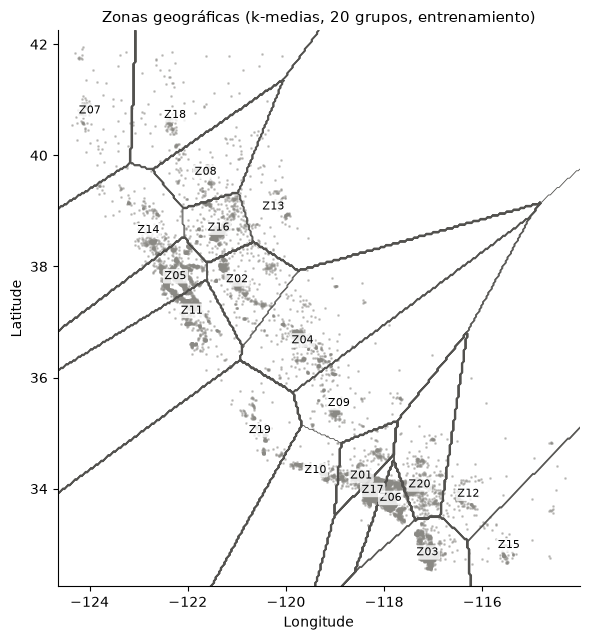

In [6]:
## Mapa de las 20 zonas: fronteras de k-medias y etiqueta en cada centroide
lon = np.linspace(X_train["Longitude"].min() - 0.3, X_train["Longitude"].max() + 0.3, 300)
lat = np.linspace(X_train["Latitude"].min() - 0.3, X_train["Latitude"].max() + 0.3, 300)
LON, LAT = np.meshgrid(lon, lat)
grilla = pd.DataFrame({"Latitude": LAT.ravel(), "Longitude": LON.ravel()})
Z = kmedias.predict(grilla).reshape(LON.shape)

fig, ax = plt.subplots(figsize=(6, 6.5))
ax.scatter(X_train["Longitude"], X_train["Latitude"], s=1, color=GRIS, alpha=0.4)
ax.contour(LON, LAT, Z, levels=np.arange(-0.5, 20.5), colors="#52514e", linewidths=0.6)
for i, (la, lo) in enumerate(kmedias.cluster_centers_):
    ax.text(lo, la, f"Z{i + 1:02d}", fontsize=8, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Zonas geográficas (k-medias, 20 grupos, entrenamiento)")
ax.grid(False)
plt.tight_layout()
plt.show()

**El preprocesador.** Seleccionamos las columnas por tipo: las numéricas con `dtype_include="number"` y las demás con `dtype_exclude="number"`.

Nota de versión: en el notebook de 2025 usamos `make_column_selector(dtype_include=object)`. Desde pandas 3.0 las columnas de texto tienen tipo `str` y no `object`; esa llamada todavía las selecciona, pero emite un aviso de obsolescencia. La forma de abajo funciona con pandas 2 y 3.

`OneHotEncoder(handle_unknown="ignore")` codifica una categoría no vista en entrenamiento como un vector de ceros, en vez de fallar. Esto será relevante en la sección 4.3, donde los pliegues de evaluación contienen zonas enteras que el modelo no vio.

In [7]:
## Preprocesador: one-hot para las categóricas y estandarización para las numéricas
preprocesador = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_exclude="number")),
    ("numericas", StandardScaler(), make_column_selector(dtype_include="number")),
])

## Pipeline completo: preprocesamiento + regresión logística multinomial
pipe_log = Pipeline([
    ("preprocesar", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000)),
])
pipe_log

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

In [8]:
## Ajustar en entrenamiento y evaluar en validación
pipe_log.fit(X_train_z, y_train_c)
f1_log_zona = f1_score(y_val_c, pipe_log.predict(X_val_z), average="macro")

## Comparación: la misma regresión logística sin la zona (como en S8)
pipe_log_sin = Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))])
pipe_log_sin.fit(X_train, y_train_c)
f1_log_sin = f1_score(y_val_c, pipe_log_sin.predict(X_val), average="macro")

print(f"Regresión logística sin zona: macro F1 (val) = {f1_log_sin:.3f}")
print(f"Regresión logística con zona: macro F1 (val) = {f1_log_zona:.3f}")

## Nombres de las columnas que recibe el modelo (20 dummies de zona + 8 numéricas)
nombres = pipe_log.named_steps["preprocesar"].get_feature_names_out()
print(len(nombres), "columnas:", list(nombres[:3]), "...", list(nombres[-2:]))

Regresión logística sin zona: macro F1 (val) = 0.525
Regresión logística con zona: macro F1 (val) = 0.562
28 columnas: ['categoricas__Zona_Z01', 'categoricas__Zona_Z02', 'categoricas__Zona_Z03'] ... ['numericas__Latitude', 'numericas__Longitude']


**Para recordar.**
- Un `Pipeline` se ajusta y se evalúa como un solo modelo: `fit`, `predict` y la validación cruzada operan sobre la secuencia completa.
- `ColumnTransformer` + `make_column_selector` separa el tratamiento de columnas numéricas y categóricas sin listas escritas a mano.
- La zona mejora la regresión logística porque le da una forma de representar la relación no lineal entre ubicación y valor que las coordenadas, por sí solas, no le permiten (recuerde las bandas paralelas de S8, sección 11).

## 3. Fuga de datos en vivo

### 3.1 La forma incorrecta y la correcta de hacer validación cruzada

**▶ En vivo.** Reproducimos el ejemplo de Hastie, Tibshirani y Friedman (2009, *The Elements of Statistical Learning*, 2.ª ed., sección 7.10.2):
- $N = 50$ casos en dos clases del mismo tamaño y $p = 5.000$ predictores gaussianos **independientes de la clase**. Es ruido puro: la exactitud (*accuracy*) verdadera de cualquier clasificador es 0,5.
- Se eligen los 100 predictores más asociados con la clase (prueba univariada) y se clasifica con el vecino más cercano (1-NN).

**Forma incorrecta:** elegir los 100 predictores con **todos** los casos y después hacer validación cruzada. Los casos que se dejan fuera ya influyeron en la selección.

**Forma correcta:** poner la selección **dentro del `Pipeline`**, para que se repita en cada partición usando solo los casos de entrenamiento de esa partición.

Usamos `SelectKBest(f_classif)`. Con dos clases, ordenar por el estadístico F equivale a ordenar por la correlación absoluta con la clase, el criterio del libro.

In [9]:
def datos_ruido(rng, n=50, p=5000):
    ## Predictores gaussianos y etiquetas balanceadas al azar: no hay ninguna señal
    X_r = rng.standard_normal((n, p))
    y_r = rng.permutation(np.repeat([0, 1], n // 2))
    return X_r, y_r


rng = np.random.default_rng(86)
X_ruido, y_ruido = datos_ruido(rng)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=86)

## INCORRECTO: la selección ve todos los casos, incluidos los que luego se dejan fuera
seleccion = SelectKBest(f_classif, k=100).fit(X_ruido, y_ruido)
acc_mal = cross_val_score(KNeighborsClassifier(n_neighbors=1), seleccion.transform(X_ruido), y_ruido, cv=cv5)

## CORRECTO: la selección es un paso del pipeline y se reajusta en cada partición
pipe_sel = Pipeline([
    ("seleccion", SelectKBest(f_classif, k=100)),
    ("modelo", KNeighborsClassifier(n_neighbors=1)),
])
acc_bien = cross_val_score(pipe_sel, X_ruido, y_ruido, cv=cv5)

print(f"Selección fuera del pipeline (incorrecto): accuracy CV = {acc_mal.mean():.3f}")
print(f"Selección dentro del pipeline (correcto):  accuracy CV = {acc_bien.mean():.3f}")
print("Verdad: 0,5 (ruido puro)")

Selección fuera del pipeline (incorrecto): accuracy CV = 1.000
Selección dentro del pipeline (correcto):  accuracy CV = 0.440
Verdad: 0,5 (ruido puro)


In [10]:
## Repetimos 50 veces, como en el libro, para ver que no es un accidente de una muestra
t0 = time.perf_counter()
res_ruido = []
for r in range(50):
    X_r, y_r = datos_ruido(rng)
    X_sel = SelectKBest(f_classif, k=100).fit_transform(X_r, y_r)
    res_ruido.append({
        "Incorrecto": cross_val_score(KNeighborsClassifier(n_neighbors=1), X_sel, y_r, cv=cv5).mean(),
        "Correcto": cross_val_score(pipe_sel, X_r, y_r, cv=cv5).mean(),
    })
res_ruido = pd.DataFrame(res_ruido)
print(f"50 simulaciones en {time.perf_counter() - t0:.1f} s")
res_ruido.agg(["mean", "std", "min", "max"]).round(3)

50 simulaciones en 6.0 s


,Incorrecto,Correcto
mean,0.991,0.498
std,0.017,0.082
min,0.940,0.360
max,1.000,0.700


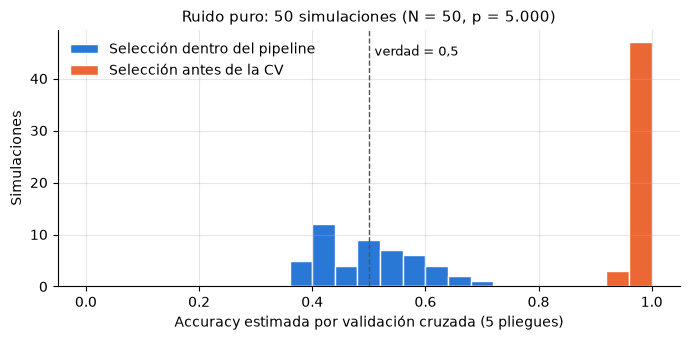

In [11]:
## Distribución de la accuracy estimada en las 50 simulaciones
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 26)
ax.hist(res_ruido["Correcto"], bins=bins, color=AZUL, edgecolor="white", label="Selección dentro del pipeline")
ax.hist(res_ruido["Incorrecto"], bins=bins, color=NARANJA, edgecolor="white", label="Selección antes de la CV")
ax.axvline(0.5, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.51, ax.get_ylim()[1] * 0.9, "verdad = 0,5", fontsize=9)
ax.set_xlabel("Accuracy estimada por validación cruzada (5 pliegues)")
ax.set_ylabel("Simulaciones")
ax.set_title("Ruido puro: 50 simulaciones (N = 50, p = 5.000)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Para recordar.**
- La forma incorrecta estima una accuracy cercana a 1 sobre ruido puro (en el libro, 3% de error promedio en 50 simulaciones); la correcta, cercana a 0,5.
- Regla de Hastie et al.: en un procedimiento de varios pasos, la validación cruzada debe aplicarse a **la secuencia completa**. Los casos se dejan fuera **antes** de cualquier selección o filtro que use la variable objetivo.
- Es la fuga L1.3 (*feature selection on training and test set*) de la taxonomía de Kapoor y Narayanan (2023, *Patterns*, 4(9), 100804).

### 3.2 Dos fugas realistas: una pequeña y una grande

No toda fuga tiene el mismo tamaño. Lo que importa es **si el paso usa la variable objetivo**.

1. **Escalar antes de dividir** (fuga L1.2, *pre-processing on training and test set*): el `StandardScaler` aprende medias y desviaciones con todas las filas. No usa la variable objetivo y, con miles de casos, las medias casi no cambian: el efecto suele ser mínimo. Igual es un error de procedimiento.
2. **Codificar con la variable objetivo antes de dividir** (*target encoding*, también L1.2). Creamos una celda geográfica fina (cuadrados de 0,02°, unos 2 km; hay miles de celdas y muchas tienen un solo caso) y la reemplazamos por la proporción de cada clase en esa celda. Si las proporciones se calculan con todas las filas, cada caso "ve" su propia etiqueta.

La versión correcta del paso 2 es `TargetEncoder` dentro del pipeline: en `fit_transform` usa **ajuste cruzado** (*cross fitting*), de modo que la codificación de un caso nunca usa su propia etiqueta.

In [12]:
## (1) Escalado: antes de la CV (incorrecto) vs dentro del pipeline (correcto)
X_escalado_todo = StandardScaler().fit_transform(X_train)
f1_esc_mal = cross_val_score(LogisticRegression(max_iter=1000), X_escalado_todo, y_train_c,
                             cv=cv5, scoring="f1_macro").mean()
f1_esc_bien = cross_val_score(pipe_log_sin, X_train, y_train_c, cv=cv5, scoring="f1_macro").mean()
print(f"Escalado antes de la CV:     macro F1 CV = {f1_esc_mal:.4f}")
print(f"Escalado dentro del pipeline: macro F1 CV = {f1_esc_bien:.4f}")
print(f"Diferencia: {f1_esc_mal - f1_esc_bien:+.4f}")

Escalado antes de la CV:     macro F1 CV = 0.5254
Escalado dentro del pipeline: macro F1 CV = 0.5254
Diferencia: -0.0000


In [13]:
def celda(df, res=0.02):
    ## Celda geográfica fina: latitud y longitud redondeadas a múltiplos de `res` grados
    return (df["Latitude"].div(res).round().astype(int).astype(str) + "_"
            + df["Longitude"].div(res).round().astype(int).astype(str))


celda_train, celda_val = celda(X_train), celda(X_val)
n_celdas = celda_train.value_counts()
print(f"Celdas en entrenamiento: {len(n_celdas):,}; con un solo caso: {(n_celdas == 1).sum():,}")

## (2a) INCORRECTO: proporción de cada clase por celda calculada con TODAS las filas de entrenamiento
props = pd.crosstab(celda_train, y_train_c, normalize="index")
X_fuga = X_train.join(props.reindex(celda_train).set_axis(X_train.index).add_prefix("p_"))
pipe_fuga = Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))])
f1_te_mal = cross_val_score(pipe_fuga, X_fuga, y_train_c, cv=cv5, scoring="f1_macro").mean()

## (2b) CORRECTO: TargetEncoder dentro del pipeline (ajuste cruzado interno, sin ver la etiqueta propia)
## Nota de versión: desde scikit-learn 1.9 los pliegues internos se pasan en cv; en versiones anteriores
## (como la de Colab) se pasan cv, shuffle y random_state por separado. Los pliegues son los mismos.
if version_al_menos("scikit-learn", "1.9"):
    pliegues_te = {"cv": StratifiedKFold(5, shuffle=True, random_state=86)}
else:
    pliegues_te = {"cv": 5, "shuffle": True, "random_state": 86}
pipe_te = Pipeline([
    ("codificar", ColumnTransformer(
        [("celda", TargetEncoder(**pliegues_te), ["Celda"])],
        remainder="passthrough")),
    ("escalar", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000)),
])
X_train_celda, X_val_celda = X_train.assign(Celda=celda_train), X_val.assign(Celda=celda_val)
f1_te_bien = cross_val_score(pipe_te, X_train_celda, y_train_c, cv=cv5, scoring="f1_macro").mean()

## ¿Se sostiene en validación? Las celdas no vistas reciben la proporción global (0,2 por clase)
pipe_fuga.fit(X_fuga, y_train_c)
X_val_fuga = X_val.join(props.reindex(celda_val).set_axis(X_val.index).fillna(0.2).add_prefix("p_"))
f1_te_mal_val = f1_score(y_val_c, pipe_fuga.predict(X_val_fuga), average="macro")
pipe_te.fit(X_train_celda, y_train_c)
f1_te_bien_val = f1_score(y_val_c, pipe_te.predict(X_val_celda), average="macro")

pd.DataFrame({
    "Macro F1 CV (entrenamiento)": [f1_te_mal, f1_te_bien],
    "Macro F1 validación": [f1_te_mal_val, f1_te_bien_val],
}, index=["Codificación antes de la CV (incorrecto)", "TargetEncoder en el pipeline (correcto)"]).round(3)

Celdas en entrenamiento: 5,295; con un solo caso: 3,037


,Macro F1 CV (entrenamiento),Macro F1 validación
Codificación antes de la CV (incorrecto),0.815,0.611
TargetEncoder en el pipeline (correcto),0.642,0.639


**Para recordar.**
- Escalar antes de dividir cambia el resultado en la cuarta cifra decimal: es un error de procedimiento con poco efecto práctico en este caso.
- Codificar con la variable objetivo antes de dividir infla mucho la estimación de la validación cruzada, y esa ventaja **desaparece** en validación, donde incluso queda por debajo de la versión correcta. La CV no detecta la fuga porque la fuga está dentro de ella.
- Bien hecha, la misma idea es útil: `TargetEncoder` en el pipeline mejora la regresión logística sin inflar la estimación.
- Regla práctica: **todo paso que aprende algo de los datos va dentro del pipeline**, y con más razón si aprende de la variable objetivo.

## 4. Validación cruzada

### 4.1 `cross_validate` con varias métricas

**▶ En vivo.** `cross_val_score` devuelve una métrica; `cross_validate` acepta varias a la vez, más los tiempos de ajuste. Usamos un random forest de 100 árboles (el más fuerte de S8 entre los rápidos) con los 8 predictores originales y 5 pliegues estratificados.

In [14]:
def crear_rf():
    return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=86)


metricas = ["f1_macro", "f1_micro", "f1_weighted", "accuracy", "balanced_accuracy"]
t0 = time.perf_counter()
cv_rf = cross_validate(crear_rf(), X_train, y_train_c, cv=cv5, scoring=metricas)
print(f"5 pliegues en {time.perf_counter() - t0:.1f} s")

pd.DataFrame({
    "Media": [cv_rf[f"test_{m}"].mean() for m in metricas],
    "DE entre pliegues": [cv_rf[f"test_{m}"].std() for m in metricas],
}, index=metricas).round(4)

5 pliegues en 1.5 s


,Media,DE entre pliegues
f1_macro,0.6739,0.0082
f1_micro,0.6744,0.0085
f1_weighted,0.6739,0.0082
accuracy,0.6744,0.0085
balanced_accuracy,0.6743,0.0085


Las cinco métricas coinciden casi exactamente, por dos razones:
- **micro F1 = accuracy** siempre que cada caso tiene una sola etiqueta (lo demostramos en la sección 6).
- Las clases son quintiles, **balanceadas por construcción**. Con pesos iguales por clase, macro, ponderado (*weighted*) y la accuracy balanceada (el promedio del *recall* de cada clase) casi no difieren. En la sección 6 veremos en qué se separan cuando las clases están desbalanceadas.

### 4.2 `KFold` vs `StratifiedKFold`

`StratifiedKFold` reparte cada clase en proporciones iguales entre los pliegues; `KFold` reparte al azar. Con 14.000 casos y clases del 20% la diferencia es pequeña. Con una clase rara, `KFold` puede dejar pliegues casi sin casos positivos, y el F1 de esa clase en ese pliegue no se puede estimar.

In [15]:
## Proporción de la clase Low en cada pliegue de evaluación
kf = KFold(n_splits=5, shuffle=True, random_state=86)
prop_low = pd.DataFrame({
    "KFold": [np.mean(y_train_c[te] == 0) for _, te in kf.split(X_train)],
    "StratifiedKFold": [np.mean(y_train_c[te] == 0) for _, te in cv5.split(X_train, y_train_c)],
}, index=[f"Pliegue {i}" for i in range(1, 6)])

## Clase rara: 200 casos con 10 positivos (5%). ¿Cuántos positivos hay en cada pliegue?
y_rara = np.random.default_rng(86).permutation(np.r_[np.ones(10), np.zeros(190)]).astype(int)
X_rara = np.zeros((200, 1))
prop_low["Positivos, KFold (clase rara)"] = [int(y_rara[te].sum()) for _, te in kf.split(X_rara)]
prop_low["Positivos, Stratified (clase rara)"] = [int(y_rara[te].sum()) for _, te in cv5.split(X_rara, y_rara)]
prop_low.round(3)

,KFold,StratifiedKFold,"Positivos, KFold (clase rara)","Positivos, Stratified (clase rara)"
Pliegue 1,0.201,0.2,1,2
Pliegue 2,0.192,0.2,1,2
Pliegue 3,0.207,0.2,0,2
Pliegue 4,0.207,0.2,4,2
Pliegue 5,0.195,0.2,4,2


### 4.3 Validación cruzada agrupada: `GroupKFold`

**▶ En vivo.** La validación cruzada supone que los casos son **independientes**. Los grupos de bloques censales no lo son: los vecinos se parecen (autocorrelación espacial). Con pliegues al azar, cada caso de evaluación tiene vecinos casi idénticos en entrenamiento, y el modelo puede "acertar" por cercanía.

`GroupKFold` asigna **zonas enteras** a cada pliegue: ninguna zona aparece a la vez en entrenamiento y evaluación. Es la fuga L3.2 de Kapoor y Narayanan (2023), *non-independence between train and test samples*; Roberts et al. (2017, *Ecography*, 40(8), 913–929) la discuten para datos espaciales, temporales y jerárquicos.

In [16]:
## Mismo modelo y mismos datos; solo cambia cómo se forman los pliegues
cv_grupos = GroupKFold(n_splits=5, shuffle=True, random_state=86)

t0 = time.perf_counter()
f1_azar = cross_val_score(crear_rf(), X_train, y_train_c, cv=cv5, scoring="f1_macro")
f1_grupos = cross_val_score(crear_rf(), X_train, y_train_c, cv=cv_grupos, groups=zonas_train, scoring="f1_macro")
print(f"10 ajustes en {time.perf_counter() - t0:.1f} s")

## Referencia: el mismo random forest ajustado en todo entrenamiento y evaluado en validación (casos al azar)
f1_rf_val = f1_score(y_val_c, crear_rf().fit(X_train, y_train_c).predict(X_val), average="macro")

print(f"StratifiedKFold (pliegues al azar):  macro F1 = {f1_azar.mean():.3f}  (pliegues: {np.round(f1_azar, 3)})")
print(f"GroupKFold (zonas completas):        macro F1 = {f1_grupos.mean():.3f}  (pliegues: {np.round(f1_grupos, 3)})")
print(f"Validación (casos al azar):          macro F1 = {f1_rf_val:.3f}")

10 ajustes en 2.8 s


StratifiedKFold (pliegues al azar):  macro F1 = 0.674  (pliegues: [0.672 0.685 0.671 0.68  0.661])
GroupKFold (zonas completas):        macro F1 = 0.443  (pliegues: [0.436 0.358 0.51  0.456 0.454])
Validación (casos al azar):          macro F1 = 0.664


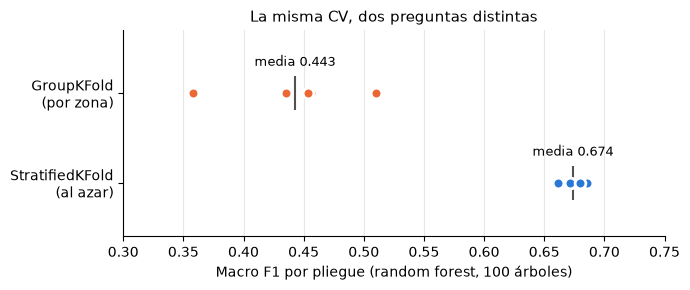

In [17]:
## Macro F1 por pliegue con cada esquema
fig, ax = plt.subplots(figsize=(7, 3))
for fila, (nombre, vals, color) in enumerate([("StratifiedKFold\n(al azar)", f1_azar, AZUL),
                                              ("GroupKFold\n(por zona)", f1_grupos, NARANJA)]):
    ax.scatter(vals, np.full(len(vals), fila), s=60, color=color, edgecolors="white", linewidths=2, zorder=3)
    ax.scatter(vals.mean(), fila, marker="|", s=600, color="#52514e", zorder=2)
    ax.text(vals.mean(), fila + 0.3, f"media {vals.mean():.3f}", ha="center", fontsize=9)
ax.set_yticks([0, 1])
ax.set_yticklabels(["StratifiedKFold\n(al azar)", "GroupKFold\n(por zona)"])
ax.set_ylim(-0.6, 1.7)
ax.set_xlim(0.3, 0.75)
ax.set_xlabel("Macro F1 por pliegue (random forest, 100 árboles)")
ax.set_title("La misma CV, dos preguntas distintas")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**¿Cuál estimación es la correcta?** Depende de la pregunta, no del código.
- Si el modelo se usará para **nuevos grupos de bloques dentro de las mismas zonas** (por ejemplo, completar datos faltantes en un censo), la CV al azar responde esa pregunta, y coincide con validación.
- Si se usará en **zonas sin datos de entrenamiento** (extender un programa de vivienda a una región nueva; en ingeniería, predecir en una planta o un sensor que el modelo no vio), la CV agrupada es la estimación honesta, y es mucho más baja. La CV al azar sería optimista.
- Con datos temporales la lógica es la misma: no se entrena con el futuro para predecir el pasado (`TimeSeriesSplit`; lo veremos en S10).

**Para recordar.**
- `cross_validate` da varias métricas y su variabilidad entre pliegues; informe la media **y** la dispersión.
- Estratifique siempre en clasificación; con clases raras es indispensable.
- Si los datos tienen grupos (personas, escuelas, hospitales, zonas, máquinas), los pliegues deben respetarlos cuando el modelo se aplicará a grupos nuevos.

## 5. Validación cruzada anidada

Si se usan los mismos pliegues para **elegir** hiperparámetros y para **informar** el desempeño, la estimación es optimista: se informa el máximo de varias estimaciones ruidosas. `GridSearchCV.best_score_` es exactamente eso.

La solución es la **validación cruzada anidada** (*nested CV*): un bucle externo estima el desempeño, y dentro de cada partición externa un bucle interno (`GridSearchCV`) elige los hiperparámetros sin ver el pliegue externo. En scikit-learn basta con pasar el `GridSearchCV` a `cross_val_score`.

Varma y Simon (2006, *BMC Bioinformatics*, 7, 91) mostraron el sesgo con datos **sin señal**, donde el error verdadero es conocido. Hacemos lo mismo y luego miramos *California Housing*.

### 5.1 Datos sin señal

60 casos, 20 predictores de ruido, dos clases. Grilla de 20 árboles de decisión (`max_depth` × `min_samples_leaf`), 5 pliegues internos y 5 externos, 10 simulaciones.

In [18]:
grilla_arbol = {"max_depth": [1, 2, 3, 4, 5], "min_samples_leaf": [1, 3, 5, 10]}

t0 = time.perf_counter()
rng_anid = np.random.default_rng(86)
res_anid = []
for r in range(10):
    X_r, y_r = datos_ruido(rng_anid, n=60, p=20)
    busqueda = GridSearchCV(DecisionTreeClassifier(random_state=86), grilla_arbol,
                            cv=StratifiedKFold(5, shuffle=True, random_state=86), scoring="accuracy")
    no_anidada = busqueda.fit(X_r, y_r).best_score_                     ## elegir e informar con los mismos pliegues
    anidada = cross_val_score(busqueda, X_r, y_r, cv=cv5, scoring="accuracy").mean()  ## bucle externo aparte
    res_anid.append({"best_score_ (no anidada)": no_anidada, "CV anidada": anidada})
res_anid = pd.DataFrame(res_anid)
print(f"10 simulaciones en {time.perf_counter() - t0:.1f} s. Verdad: accuracy = 0,5")
res_anid.agg(["mean", "std"]).round(3)

10 simulaciones en 13.0 s. Verdad: accuracy = 0,5


,best_score_ (no anidada),CV anidada
mean,0.570,0.493
std,0.074,0.075


### 5.2 *California Housing*

Grilla pequeña para el random forest (`max_depth` ∈ {8, 16, sin límite}), 5 pliegues internos y 5 externos. Usamos 5 pliegues en ambos bucles para que los modelos se entrenen con tamaños parecidos y la comparación no dependa del tamaño de la muestra.

In [19]:
busqueda_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=86),
    {"max_depth": [8, 16, None]},
    cv=StratifiedKFold(5, shuffle=True, random_state=86), scoring="f1_macro",
)
t0 = time.perf_counter()
busqueda_rf.fit(X_train, y_train_c)
f1_anidada = cross_val_score(busqueda_rf, X_train, y_train_c,
                             cv=StratifiedKFold(5, shuffle=True, random_state=87), scoring="f1_macro")
print(f"Búsqueda + CV anidada en {time.perf_counter() - t0:.1f} s")
print(f"Mejor configuración: {busqueda_rf.best_params_}")
print(f"best_score_ (no anidada): {busqueda_rf.best_score_:.4f}")
print(f"CV anidada:               {f1_anidada.mean():.4f}  (DE {f1_anidada.std():.4f})")

Búsqueda + CV anidada en 15.3 s
Mejor configuración: {'max_depth': None}
best_score_ (no anidada): 0.6718
CV anidada:               0.6677  (DE 0.0094)


**Para recordar.**
- Con datos sin señal, `best_score_` promete una accuracy por encima de 0,5 y la CV anidada vuelve a 0,5: el optimismo viene solo de **elegir el máximo**.
- En *California Housing*, con 3 configuraciones y 14.000 casos, la diferencia es pequeña: menor que la variación entre pliegues. El sesgo crece con **el número de configuraciones** probadas y con **la variabilidad** de la estimación (muestras pequeñas, como en muchos estudios de ciencias sociales o biomédicos).
- La CV anidada estima el desempeño del **procedimiento** ("buscar en esta grilla y ajustar"), no de una configuración fija. Para elegir el modelo final se usa `GridSearchCV` en todos los datos de entrenamiento; para informar cuánto rinde, la CV anidada o un conjunto de prueba intacto.

## 6. Métricas multiclase

**▶ En vivo.** Ajustamos un random forest de 300 árboles (modelo de referencia para las secciones 6 y 7) y lo evaluamos en validación. Para cada clase $k$ se calculan precisión, *recall* y F1 tratando a $k$ como positiva y al resto como negativa. Luego se resumen de tres formas:

| Promedio | Cómo se calcula | Qué privilegia |
|---|---|---|
| **macro** | promedio simple de los F1 de cada clase | cada clase pesa igual (métrica del desafío) |
| **ponderado** (*weighted*) | promedio de los F1 ponderado por el número de casos de cada clase | las clases grandes |
| **micro** | suma VP, FP y FN de todas las clases y luego calcula un único F1 | cada caso pesa igual |

In [20]:
## Modelo de referencia para las secciones 6 y 7
rf_ref = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=86).fit(X_train, y_train_c)
pred_val = rf_ref.predict(X_val)
print(classification_report(y_val_c, pred_val, target_names=etiquetas, digits=3))

              precision    recall  f1-score   support

         Low      0.773     0.801     0.787       648
  Medium-Low      0.599     0.642     0.620       612
      Medium      0.583     0.556     0.569       603
 Medium-High      0.595     0.582     0.589       601
        High      0.797     0.764     0.780       632

    accuracy                          0.672      3096
   macro avg      0.669     0.669     0.669      3096
weighted avg      0.672     0.672     0.672      3096



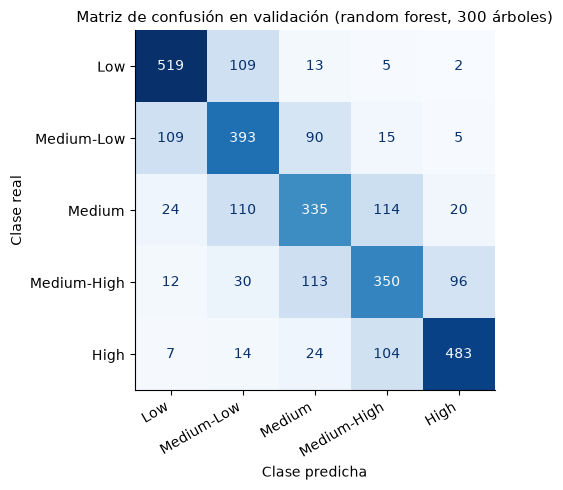

In [21]:
## Matriz de confusión en validación
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val_c, pred_val, display_labels=etiquetas,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matriz de confusión en validación (random forest, 300 árboles)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.grid(False)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Macro, ponderado y micro a mano.** Partimos del F1 de cada clase y de la matriz de confusión.

¿Por qué **micro F1 = accuracy**? Con una sola etiqueta por caso, cada error es a la vez un falso positivo (de la clase predicha) y un falso negativo (de la clase real). Entonces $\sum_k \text{FP}_k = \sum_k \text{FN}_k$, la precisión micro y el *recall* micro son iguales, y ambos son iguales a aciertos / total.

In [22]:
f1_clase = f1_score(y_val_c, pred_val, average=None)        ## un F1 por clase
soporte = np.bincount(y_val_c)                              ## casos reales por clase
mc = confusion_matrix(y_val_c, pred_val)

vp = np.diag(mc)                        ## verdaderos positivos de cada clase
fp = mc.sum(axis=0) - vp                ## columna menos diagonal
fn = mc.sum(axis=1) - vp                ## fila menos diagonal

macro_mano = f1_clase.mean()
ponderado_mano = np.sum(f1_clase * soporte) / soporte.sum()
micro_mano = 2 * vp.sum() / (2 * vp.sum() + fp.sum() + fn.sum())

print(pd.DataFrame({"F1": f1_clase, "Soporte": soporte, "VP": vp, "FP": fp, "FN": fn}, index=etiquetas).round(3))
print(f"\nSuma de FP = {fp.sum()} | suma de FN = {fn.sum()}")
print(f"Macro F1:     a mano {macro_mano:.4f} | scikit-learn {f1_score(y_val_c, pred_val, average='macro'):.4f}")
print(f"Ponderado F1: a mano {ponderado_mano:.4f} | scikit-learn {f1_score(y_val_c, pred_val, average='weighted'):.4f}")
print(f"Micro F1:     a mano {micro_mano:.4f} | scikit-learn {f1_score(y_val_c, pred_val, average='micro'):.4f}"
      f" | accuracy {accuracy_score(y_val_c, pred_val):.4f}")

                F1  Soporte   VP   FP   FN
Low          0.787      648  519  152  129
Medium-Low   0.620      612  393  263  219
Medium       0.569      603  335  240  268
Medium-High  0.589      601  350  238  251
High         0.780      632  483  123  149



Suma de FP = 1016 | suma de FN = 1016
Macro F1:     a mano 0.6689 | scikit-learn 0.6689
Ponderado F1: a mano 0.6716 | scikit-learn 0.6716
Micro F1:     a mano 0.6718 | scikit-learn 0.6718 | accuracy 0.6718


**¿Dónde se separan?** Aquí las clases están balanceadas y los tres promedios casi coinciden. Para verlos separarse, evaluamos **el mismo modelo con las mismas predicciones** en una submuestra de validación con clases desbalanceadas: 45% `Low`, 25% `Medium-Low`, 15% `Medium`, 10% `Medium-High` y 5% `High`.

In [23]:
## Submuestra desbalanceada de validación (mismas predicciones, otra composición)
rng_desb = np.random.default_rng(86)
cuotas = {0: 585, 1: 325, 2: 195, 3: 130, 4: 65}   ## 1.300 casos: 45/25/15/10/5%
idx_desb = np.concatenate([rng_desb.choice(np.flatnonzero(y_val_c == k), n, replace=False)
                           for k, n in cuotas.items()])

comparacion_prom = pd.DataFrame({
    promedio: [f1_score(y_val_c, pred_val, average=promedio),
               f1_score(y_val_c[idx_desb], pred_val[idx_desb], average=promedio)]
    for promedio in ["macro", "weighted", "micro"]
}, index=["Validación (balanceada)", "Submuestra desbalanceada"])
print(comparacion_prom.round(3))
print("\nF1 por clase en la submuestra desbalanceada:")
print(pd.Series(f1_score(y_val_c[idx_desb], pred_val[idx_desb], average=None), index=etiquetas).round(3))

                          macro  weighted  micro
Validación (balanceada)   0.669     0.672  0.672
Submuestra desbalanceada  0.655     0.708  0.705

F1 por clase en la submuestra desbalanceada:
Low            0.837
Medium-Low     0.619
Medium         0.581
Medium-High    0.563
High           0.676
dtype: float64


**Para recordar.**
- Con clases desbalanceadas, el F1 ponderado y el micro quedan dominados por la clase grande; el macro F1 hace visible el mal desempeño en las clases pequeñas.
- El F1 de una clase depende de su prevalencia: con menos casos de `High`, la misma tasa de errores produce más falsos positivos **en proporción** y su precisión cae.
- Por eso el desafío usa **macro F1**: un modelo que ignora una clase lo paga, aunque sea pequeña.

## 7. Curvas ROC y PR para una clase

**▶ En vivo.** Tomamos una sola clase, `Low`, contra el resto (*one-vs-rest*). Es análogo a focalizar un programa en el grupo de menor valor (o menor ingreso): lo que interesa es encontrar a los positivos. El puntaje es la probabilidad $\hat P(\text{Low})$ que entrega cada modelo.
- **Curva ROC**: tasa de verdaderos positivos (*recall*) contra tasa de falsos positivos al mover el umbral. Resumen: **AUC**.
- **Curva PR**: precisión contra *recall*. Resumen: **precisión promedio** (*average precision*, AP). Su línea de azar es la prevalencia de la clase positiva.

Comparamos el random forest de la sección 6 con la regresión logística sin zona de la sección 2, primero con la prevalencia real de `Low` en validación (~20%) y luego en una submuestra donde `Low` es el **5%** (conservamos todos los negativos y una muestra de los positivos). Saito y Rehmsmeier (2015, *PLoS ONE*, 10(3), e0118432) muestran que, con clases desbalanceadas, la curva PR es más informativa que la ROC.

In [24]:
## Puntajes de la clase Low (columna 0) para los dos modelos
y_val_low = (y_val_c == 0).astype(int)
puntajes = {
    "Random forest": rf_ref.predict_proba(X_val)[:, 0],
    "Regresión logística": pipe_log_sin.predict_proba(X_val)[:, 0],
}

## Submuestra con 5% de positivos: todos los negativos y una muestra aleatoria de los positivos
neg, pos = np.flatnonzero(y_val_low == 0), np.flatnonzero(y_val_low == 1)
n_pos = int(round(0.05 / 0.95 * len(neg)))
idx_5 = np.concatenate([neg, np.random.default_rng(86).choice(pos, n_pos, replace=False)])
escenarios = {
    f"Prevalencia {y_val_low.mean():.0%}": np.arange(len(y_val_low)),
    f"Prevalencia {y_val_low[idx_5].mean():.0%}": idx_5,
}

filas = []
for esc, idx in escenarios.items():
    for nombre, s in puntajes.items():
        filas.append({"Escenario": esc, "Modelo": nombre, "Casos": len(idx),
                      "ROC AUC": roc_auc_score(y_val_low[idx], s[idx]),
                      "Average precision": average_precision_score(y_val_low[idx], s[idx])})
tabla_roc_pr = pd.DataFrame(filas).set_index(["Escenario", "Modelo"])
tabla_roc_pr.round(3)

Casos  ROC AUC  Average precision
Escenario       Modelo                                                
Prevalencia 21% Random forest         3096    0.965              0.880
                Regresión logística   3096    0.920              0.713
Prevalencia 5%  Random forest         2577    0.962              0.658
                Regresión logística   2577    0.923              0.395

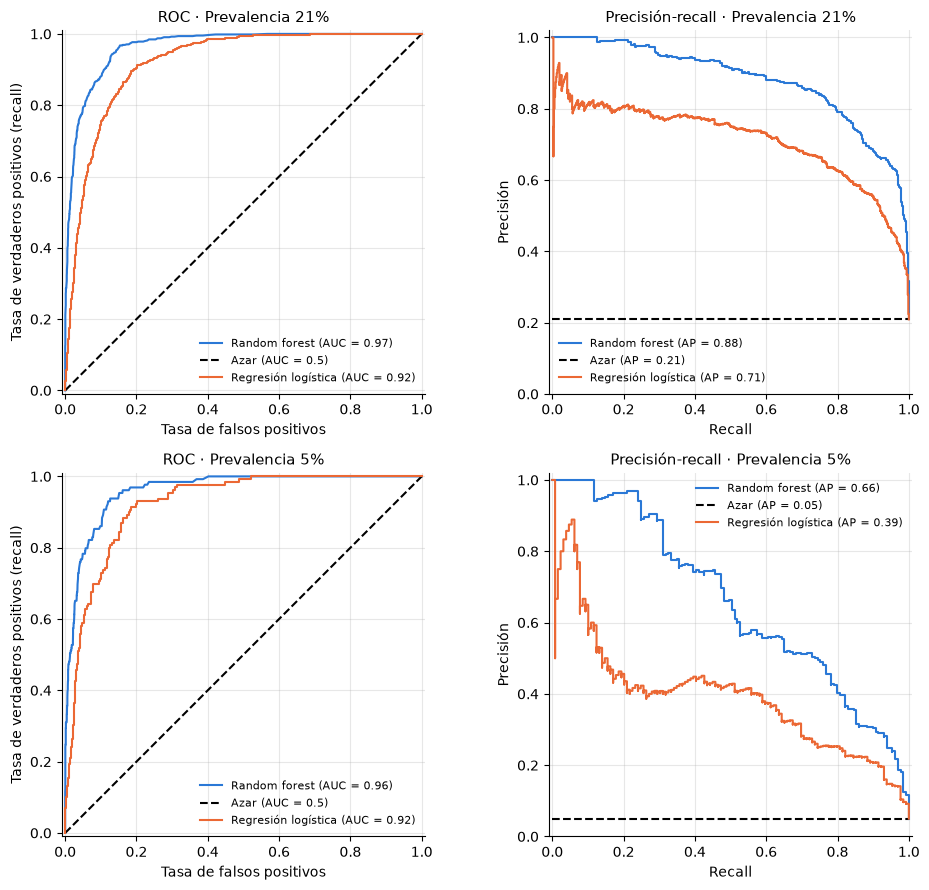

In [25]:
## Nota de versión: desde scikit-learn 1.7 el estilo de la curva se pasa en curve_kwargs;
## en versiones anteriores (como la de Colab), directamente como argumento
def estilo_curva(color):
    if "curve_kwargs" in inspect.signature(RocCurveDisplay.from_predictions).parameters:
        return {"curve_kwargs": {"color": color}}
    return {"color": color}


## Curvas ROC (izquierda) y PR (derecha) en los dos escenarios
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for fila, (esc, idx) in enumerate(escenarios.items()):
    for j, (nombre, color) in enumerate([("Random forest", AZUL), ("Regresión logística", NARANJA)]):
        s = puntajes[nombre][idx]
        RocCurveDisplay.from_predictions(y_val_low[idx], s, name=nombre, ax=axes[fila, 0],
                                         **estilo_curva(color), plot_chance_level=(j == 0))
        PrecisionRecallDisplay.from_predictions(y_val_low[idx], s, name=nombre, ax=axes[fila, 1],
                                                **estilo_curva(color), plot_chance_level=(j == 0))
    axes[fila, 0].set_title(f"ROC · {esc}")
    axes[fila, 0].set_xlabel("Tasa de falsos positivos")
    axes[fila, 0].set_ylabel("Tasa de verdaderos positivos (recall)")
    axes[fila, 1].set_title(f"Precisión-recall · {esc}")
    axes[fila, 1].set_xlabel("Recall")
    axes[fila, 1].set_ylabel("Precisión")
    axes[fila, 1].set_ylim(0, 1.02)
    for ax, loc in [(axes[fila, 0], "lower right"), (axes[fila, 1], "lower left" if fila == 0 else "upper right")]:
        h, l = ax.get_legend_handles_labels()
        ax.legend(h, [t.replace("Chance level", "Azar") for t in l], frameon=False, fontsize=8, loc=loc)
plt.tight_layout()
plt.show()

**Para recordar.**
- La curva ROC y su AUC **casi no cambian** al pasar del 20% al 5% de positivos. La tasa de falsos positivos se calcula sobre los negativos, que siguen siendo muchos, y no refleja cuántos de los casos señalados son en verdad positivos.
- La curva PR **sí cambia**: con 5% de positivos, la precisión cae a cualquier nivel de *recall* y la AP baja mucho, sobre todo en el modelo más débil. Eso es lo que vive quien usa el modelo: de cada 100 casos señalados, cuántos son `Low`.
- Con una clase positiva rara (fraude, fallas, beneficiarios de un programa), informe la curva PR y la AP, junto con su línea de azar (la prevalencia).

## 8. Umbrales y costos

`predict` clasifica con un umbral implícito de 0,5 en el caso binario. Ese umbral rara vez es el adecuado: los errores no cuestan lo mismo.

**Situación** (cifras hipotéticas). Un programa de subsidio a la vivienda se focaliza en las zonas `Low`.
- Dejar fuera una zona que lo necesita (**falso negativo**) cuesta **5** unidades.
- Incluir una zona que no lo necesita (**falso positivo**) cuesta **1** unidad.

En ingeniería, la detección de fallas tiene la misma estructura: una falla no detectada suele costar mucho más que una alarma falsa.

**Procedimiento sin fuga.** El umbral es un hiperparámetro más: lo elegimos con probabilidades **fuera de la muestra** de entrenamiento (`cross_val_predict`, 5 pliegues) y lo evaluamos en validación.

In [26]:
## Tarea binaria: Low (1) contra el resto (0)
y_train_low = (y_train_c == 0).astype(int)
rf_bin = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=86)

## Probabilidades fuera de la muestra en entrenamiento (cada caso predicho por un modelo que no lo vio)
p_oof = cross_val_predict(rf_bin, X_train, y_train_low, cv=cv5, method="predict_proba")[:, 1]

COSTO_FN, COSTO_FP = 5, 1     ## cifras hipotéticas


def costo_total(y_true, p, umbral):
    pred = (p >= umbral).astype(int)
    fn = int(((pred == 0) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    return COSTO_FN * fn + COSTO_FP * fp, fn, fp


filas = []
for u in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    c, fn, fp = costo_total(y_train_low, p_oof, u)
    pred = (p_oof >= u).astype(int)
    filas.append({"Umbral": u, "Precisión": precision_score(y_train_low, pred),
                  "Recall": recall_score(y_train_low, pred), "FN": fn, "FP": fp, "Costo total": c})
pd.DataFrame(filas).set_index("Umbral").round(3)

,Precisión,Recall,FN,FP,Costo total
Umbral,,,,,
0.1,0.512,0.978,65,2700,3025
0.2,0.633,0.945,158,1587,2377
0.3,0.720,0.897,298,1012,2502
0.4,0.801,0.836,476,601,2981
0.5,0.854,0.758,701,376,3881
0.6,0.894,0.667,963,228,5043
0.7,0.934,0.561,1271,115,6470


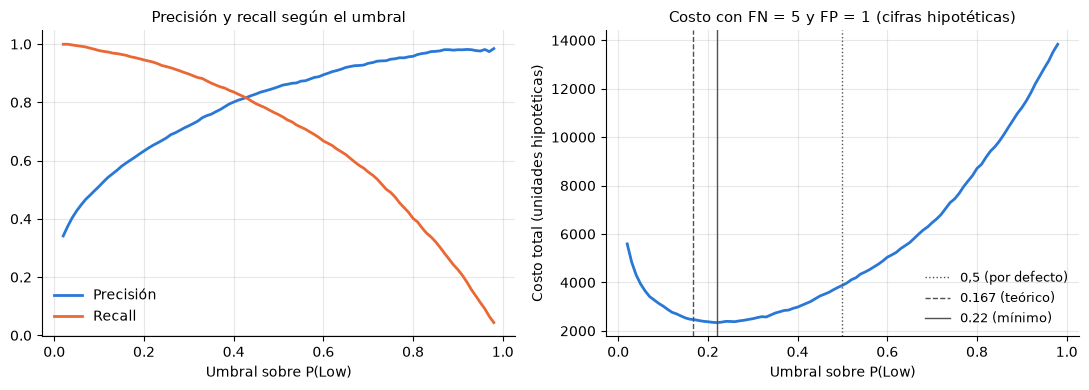

In [27]:
## Curvas de precisión, recall y costo según el umbral (probabilidades fuera de la muestra)
umbrales = np.round(np.arange(0.02, 0.99, 0.01), 2)
costos = np.array([costo_total(y_train_low, p_oof, u)[0] for u in umbrales])
prec = [precision_score(y_train_low, (p_oof >= u).astype(int), zero_division=0) for u in umbrales]
rec = [recall_score(y_train_low, (p_oof >= u).astype(int)) for u in umbrales]
umbral_opt = umbrales[np.argmin(costos)]
umbral_teo = COSTO_FP / (COSTO_FP + COSTO_FN)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(umbrales, prec, color=AZUL, linewidth=2, label="Precisión")
axes[0].plot(umbrales, rec, color=NARANJA, linewidth=2, label="Recall")
axes[0].set_xlabel("Umbral sobre P(Low)")
axes[0].set_title("Precisión y recall según el umbral")
axes[0].legend(frameon=False)

axes[1].plot(umbrales, costos, color=AZUL, linewidth=2)
for u, etiqueta, ls in [(0.5, "0,5 (por defecto)", ":"), (umbral_teo, f"{umbral_teo:.3f} (teórico)", "--"),
                        (umbral_opt, f"{umbral_opt:.2f} (mínimo)", "-")]:
    axes[1].axvline(u, color="#52514e", linestyle=ls, linewidth=1, label=etiqueta)
axes[1].set_xlabel("Umbral sobre P(Low)")
axes[1].set_ylabel("Costo total (unidades hipotéticas)")
axes[1].set_title("Costo con FN = 5 y FP = 1 (cifras hipotéticas)")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [28]:
## Evaluación en validación: umbral por defecto vs umbral elegido en entrenamiento
rf_bin.fit(X_train, y_train_low)
p_val_rf = rf_bin.predict_proba(X_val)[:, 1]
filas = []
for nombre, u in [("Por defecto", 0.5), ("Teórico c_FP / (c_FP + c_FN)", umbral_teo), ("Mínimo costo (CV)", umbral_opt)]:
    c, fn, fp = costo_total(y_val_low, p_val_rf, u)
    pred = (p_val_rf >= u).astype(int)
    filas.append({"Umbral": nombre, "Valor": round(u, 3), "Precisión": precision_score(y_val_low, pred),
                  "Recall": recall_score(y_val_low, pred), "FN": fn, "FP": fp, "Costo total": c})
pd.DataFrame(filas).set_index("Umbral").round(3)

,Valor,Precisión,Recall,FN,FP,Costo total
Umbral,,,,,,
Por defecto,0.500,0.841,0.741,168,91,931
Teórico c_FP / (c_FP + c_FN),0.167,0.605,0.955,29,404,549
Mínimo costo (CV),0.220,0.637,0.931,45,343,568


**Para recordar.**
- Bajar el umbral sube el *recall* y baja la precisión. El punto adecuado depende de los costos, que son una decisión sustantiva (de política o de ingeniería), no estadística.
- Si las probabilidades están **bien calibradas** (sección 9), el umbral que minimiza el costo esperado es $c_{FP} / (c_{FP} + c_{FN})$, aquí 1/6 ≈ 0,167. El umbral empírico (0,22) queda cerca, pero no coincide: las probabilidades del random forest no están perfectamente calibradas.
- En validación, ambos umbrales reducen el costo en alrededor de 40% respecto de 0,5. Que el teórico rinda aquí algo mejor que el elegido por CV recuerda que el umbral elegido también es una estimación con ruido.
- El umbral se elige con datos de entrenamiento (fuera de la muestra) y se evalúa en datos que no participaron en la elección. scikit-learn automatiza este paso con `TunedThresholdClassifierCV`.

## 9. Calibración

Un clasificador está **calibrado** si, entre los casos a los que asigna probabilidad 0,3, alrededor del 30% son positivos. La AUC mide **discriminación** (ordenar bien); la calibración mide si las probabilidades **significan lo que dicen**. Importa cuando la probabilidad se usa como tal: umbrales por costo (sección 8), priorización o estimación de cuántos casos habrá.

- **Diagrama de confiabilidad** (*reliability diagram*): agrupa las predicciones en intervalos y compara la probabilidad media predicha con la proporción observada. Un modelo calibrado queda sobre la diagonal.
- **Puntaje de Brier** (Brier, 1950): error cuadrático medio de la probabilidad, $\frac{1}{n}\sum_i (\hat p_i - y_i)^2$. Menor es mejor. Combina calibración y discriminación.

Comparamos tres modelos en la tarea binaria `Low` contra el resto (Niculescu-Mizil y Caruana, 2005, hacen esta comparación con muchos más modelos), más una versión recalibrada de Naive Bayes con `CalibratedClassifierCV` (regresión isotónica, 5 pliegues internos).

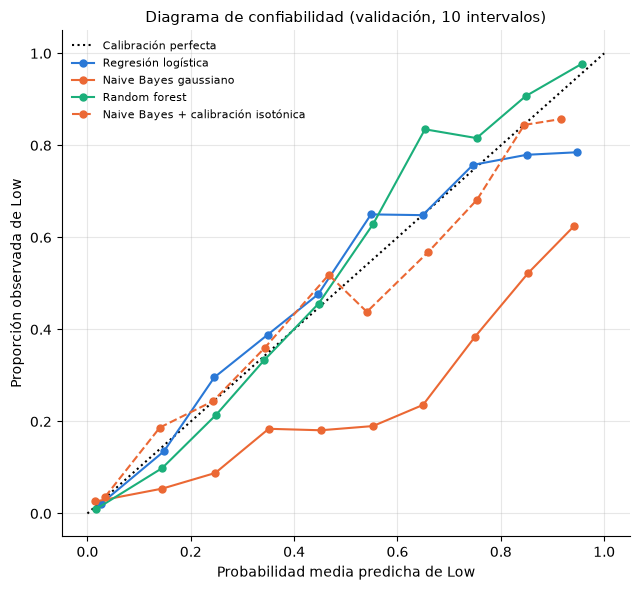

,Brier,ROC AUC
Modelo,,
Regresión logística,0.0933,0.9171
Naive Bayes gaussiano,0.1858,0.8333
Random forest,0.0623,0.9622
Naive Bayes + calibración isotónica,0.1231,0.8355
Referencia: prevalencia constante,0.1656,0.5000


In [29]:
modelos_cal = {
    "Regresión logística": Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))]),
    "Naive Bayes gaussiano": GaussianNB(),
    "Random forest": rf_bin,     ## ya ajustado en la sección 8
    "Naive Bayes + calibración isotónica": CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=cv5),
}
for nombre, m in modelos_cal.items():
    if nombre != "Random forest":
        m.fit(X_train, y_train_low)

fig, ax = plt.subplots(figsize=(6.5, 6))
estilos = {"Regresión logística": (AZUL, "-"), "Naive Bayes gaussiano": (NARANJA, "-"),
           "Random forest": (VERDE, "-"), "Naive Bayes + calibración isotónica": (NARANJA, "--")}
filas = []
for i, (nombre, m) in enumerate(modelos_cal.items()):
    color, ls = estilos[nombre]
    CalibrationDisplay.from_estimator(m, X_val, y_val_low, n_bins=10, name=nombre, ax=ax,
                                      ref_line=(i == 0), color=color, linestyle=ls, marker="o", markersize=5)
    p = m.predict_proba(X_val)[:, 1]
    filas.append({"Modelo": nombre, "Brier": brier_score_loss(y_val_low, p), "ROC AUC": roc_auc_score(y_val_low, p)})
ax.set_xlabel("Probabilidad media predicha de Low")
ax.set_ylabel("Proporción observada de Low")
ax.set_title("Diagrama de confiabilidad (validación, 10 intervalos)")
h, l = ax.get_legend_handles_labels()
ax.legend(h, [t.replace("Perfectly calibrated", "Calibración perfecta") for t in l],
          frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## Referencia: predecir siempre la prevalencia de entrenamiento (sin discriminación, calibrado en promedio)
filas.append({"Modelo": "Referencia: prevalencia constante",
              "Brier": brier_score_loss(y_val_low, np.full(len(y_val_low), y_train_low.mean())), "ROC AUC": 0.5})
pd.DataFrame(filas).set_index("Modelo").round(4)

**Para recordar.**
- Naive Bayes ordena razonablemente bien (AUC > 0,8), pero **sobreestima la probabilidad de `Low` en casi todo el rango**: su curva queda bajo la diagonal y su Brier es **peor que predecir siempre la prevalencia**. Su supuesto de independencia condicional, falso con predictores tan correlacionados, distorsiona las probabilidades.
- La recalibración isotónica casi no cambia el orden de los casos (la AUC apenas se mueve), pero acerca la curva a la diagonal y reduce mucho el Brier.
- La regresión logística queda cerca de la diagonal salvo en el tramo alto, donde es algo sobreconfiada; optimiza directamente la verosimilitud de las probabilidades. El random forest es conservador en el tramo medio (su curva queda sobre la diagonal) y aun así tiene el mejor Brier, sobre todo porque discrimina mejor.
- Recalibre con datos que el modelo no usó para ajustarse (`CalibratedClassifierCV` lo hace con pliegues internos).

## 10. Métricas de regresión

Si tratamos `MedHouseVal` como continua (cientos de miles de USD), las métricas cambian:

| Métrica | Fórmula | Lectura |
|---|---|---|
| **MSE** | $\frac{1}{n}\sum (y_i - \hat y_i)^2$ | penaliza mucho los errores grandes; unidades al cuadrado |
| **RMSE** | $\sqrt{\text{MSE}}$ | en las unidades de $y$ |
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat y_i\rvert$ | error típico, menos sensible a valores extremos |
| **R²** | $1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$ | proporción de la varianza explicada respecto de predecir la media; puede ser negativo |

La línea base es `DummyRegressor`, que predice siempre la media de entrenamiento (R² ≈ 0).

In [30]:
t0 = time.perf_counter()
reg_rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=86).fit(X_train, y_train)
regresores = {"Dummy (media)": DummyRegressor().fit(X_train, y_train), "Random forest (200 árboles)": reg_rf}
filas = []
for nombre, m in regresores.items():
    pr = m.predict(X_val)
    filas.append({"Modelo": nombre, "MSE": mean_squared_error(y_val, pr), "RMSE": root_mean_squared_error(y_val, pr),
                  "MAE": mean_absolute_error(y_val, pr), "R²": r2_score(y_val, pr)})
print(f"Ajuste en {time.perf_counter() - t0:.1f} s")
tabla_reg = pd.DataFrame(filas).set_index("Modelo")
tabla_reg.round(3)

Ajuste en 1.1 s


,MSE,RMSE,MAE,R²
Modelo,,,,
Dummy (media),1.364,1.168,0.926,-0.000
Random forest (200 árboles),0.271,0.521,0.341,0.801


In [31]:
r = tabla_reg.loc["Random forest (200 árboles)"]
print(f"RMSE = {r['RMSE']:.3f} → un error típico de unos {r['RMSE'] * 100_000:,.0f} USD; "
      f"MAE = {r['MAE']:.3f} → {r['MAE'] * 100_000:,.0f} USD.")
print(f"Casos de validación con el valor en el tope de 5,0 (500.000 USD o más): {(y_val >= 5).sum()}")

RMSE = 0.521 → un error típico de unos 52,051 USD; MAE = 0.341 → 34,134 USD.
Casos de validación con el valor en el tope de 5,0 (500.000 USD o más): 154


**Para recordar.**
- RMSE ≥ MAE siempre; una brecha grande indica errores grandes concentrados en pocos casos.
- R² compara con predecir la media: no dice si el error es aceptable para el uso previsto, y un R² alto no implica un RMSE pequeño en las unidades que importan.
- Aquí la variable tiene un tope (*censura*) en 5,0: el modelo no puede distinguir entre 500.000 USD y valores mayores, lo que limita cualquier métrica en ese tramo.
- Todo lo anterior sobre fuga, CV agrupada y anidada vale igual para regresión.

## 11. Ejercicios

### (a) Un pipeline para reparar: indicadores del Banco Mundial

Este es el ejercicio de 2025. Una analista quiere predecir la **esperanza de vida al nacer** de cada país y año (2010–2020) con indicadores del Banco Mundial, usando un random forest. Su código, reproducido abajo, **corre sin errores hasta la definición del pipeline, pero contiene varios problemas**, algunos silenciosos. La última celda, que intenta evaluar el modelo, falla.

**Tareas.**
1. ¿Por qué falla la última celda? Complete el flujo: ajuste y evalúe con MSE, RMSE, MAE y R² (sección 10).
2. Inspeccione `X`. ¿Qué columnas quedaron? ¿Por qué `filter` no avisó nada?
3. Inspeccione la columna `country`. ¿Son todas países? ¿Qué problema crean las filas que no lo son?
4. Una vez corregida la selección de predictores, ¿hay valores faltantes en `X`? El random forest de scikit-learn ≥ 1.4 acepta `NaN`, pero la mayoría de los modelos no (pruebe con `LinearRegression`). Decida cómo tratarlos y hágalo **dentro del pipeline**.
5. Los datos son un **panel país-año**. ¿Qué ocurre con un mismo país al dividir al azar con `train_test_split`? Compare con una división por país (`GroupShuffleSplit` o `GroupKFold`; sección 4.3). ¿Qué pregunta responde cada estimación?
6. ¿Es necesario el `StandardScaler` en un random forest?
7. El renombrado de columnas asigna los nombres por **posición**. ¿Qué pasaría si se agregara un indicador? Proponga una forma más segura.
8. Discusión: ¿debería usarse la mortalidad infantil (`mortality`) como predictor de la esperanza de vida?

**Sobre los datos.** En 2025 usamos el paquete `wbgapi`. Verificado el 12 de octubre de 2026: la API del Banco Mundial y los seis indicadores siguen respondiendo, pero la primera consulta con `wbgapi` tardó unos 4 minutos. Por eso la descarga usa una función propia que consulta la **misma API pública** con la librería estándar de Python (sin paquetes adicionales) y devuelve la misma tabla que `wb.data.DataFrame(indicadores, time=range(2010, 2021), labels=True)`. La función no es parte del ejercicio: no necesita revisarla. Si la API tarda, vuelva a ejecutar la celda; las consultas repetidas suelen responder en segundos.

In [32]:
## Función de descarga (no forma parte del ejercicio): misma tabla que wbgapi con labels=True
import json
import urllib.request


def descargar_banco_mundial(indicadores, desde=2010, hasta=2020, timeout=300):
    filas = []
    for codigo in indicadores:
        url = (f"https://api.worldbank.org/v2/country/all/indicator/{codigo}"
               f"?format=json&date={desde}:{hasta}&per_page=20000")
        with urllib.request.urlopen(url, timeout=timeout) as respuesta:
            _, datos = json.load(respuesta)
        filas += [{"economy": d["countryiso3code"], "Country": d["country"]["value"],
                   "Series": d["indicator"]["value"], "year": f"YR{d['date']}", "value": d["value"]}
                  for d in datos]
    largo = pd.DataFrame(filas)
    ancho = largo.pivot(index=["economy", "Country", "Series"], columns="year", values="value")
    ancho.columns.name = None
    return ancho.reset_index(["Country", "Series"])

In [33]:
## ---- Código de la analista (2025) ----
## Dependencies
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [34]:
## Indicadores: PIB, Población y Tasa de mortalidad infantil
indicadores = ["NY.GDP.MKTP.CD",     ## PIB (USD)
               "SP.POP.TOTL",        ## Población total
               "SP.DYN.IMRT.IN",     ## Tasa de mortalidad infantil (por 1,000 nacidos vivos)
               "NY.GDP.PCAP.CD",     ## PIB per cápita (USD)
               "SP.URB.TOTL.IN.ZS",  ## Población urbana (% del total)
               "SP.DYN.LE00.IN"]     ## Esperanza de vida al nacer (años)

## Descargar datos para el periodo 2010-2020
t0 = time.perf_counter()
datos_wb = descargar_banco_mundial(indicadores, desde=2010, hasta=2020)
print(f"Descarga: {time.perf_counter() - t0:.1f} s | {datos_wb.shape[0]} filas (economía × indicador)")

Descarga: 1.7 s | 1596 filas (economía × indicador)


In [35]:
## Pivotear la tabla para tener los años como filas en lugar de columnas
datos_wb = datos_wb.melt(id_vars=["Country", "Series"], var_name="year", value_name="value")

## Pivotear las series para que cada indicador sea una columna
datos_wb_pivot = datos_wb.pivot_table(index=["Country", "year"], columns="Series", values="value").reset_index()

## Inspeccionar
datos_wb_pivot.head()

Series,Country,year,GDP (current US$),GDP per capita (current US$),"Life expectancy at birth, total (years)","Mortality rate, infant (per 1,000 live births)","Population, total",Urban population (% of total population)
0,Afghanistan,YR2010,1.585667e+10,560.621505,60.702,76.9,28284089.0,22.261480
1,Afghanistan,YR2011,1.780510e+10,606.694676,61.250,74.0,29347708.0,22.820569
2,Afghanistan,YR2012,1.990733e+10,651.417134,61.735,71.2,30560034.0,23.343439
3,Afghanistan,YR2013,2.014642e+10,637.087099,62.188,68.6,31622704.0,23.807714
4,Afghanistan,YR2014,2.049713e+10,625.054942,62.260,66.2,32792523.0,24.191017


In [36]:
## Renombrar las columnas para que sean más legibles
datos_wb_pivot.columns = ["country", "year", "gdp_current", "gdp_pp", "life_exp", "mortality", "population", "urban_pop"]

## Inspeccionar
datos_wb_pivot.head()

,country,year,gdp_current,gdp_pp,life_exp,mortality,population,urban_pop
0,Afghanistan,YR2010,1.585667e+10,560.621505,60.702,76.9,28284089.0,22.261480
1,Afghanistan,YR2011,1.780510e+10,606.694676,61.250,74.0,29347708.0,22.820569
2,Afghanistan,YR2012,1.990733e+10,651.417134,61.735,71.2,30560034.0,23.343439
3,Afghanistan,YR2013,2.014642e+10,637.087099,62.188,68.6,31622704.0,23.807714
4,Afghanistan,YR2014,2.049713e+10,625.054942,62.260,66.2,32792523.0,24.191017


In [37]:
X_wb = datos_wb_pivot.filter(items=[
    "gdp",
    "population",
    "urban_pop",
])
y_wb = datos_wb_pivot["life_exp"]  ## Outcome

## Dividir los datos en conjuntos de entrenamiento y prueba
X_wb_train, X_wb_test, y_wb_train, y_wb_test = train_test_split(X_wb, y_wb, test_size=0.2, random_state=86)

## Crear el pipeline de preprocesamiento y modelo
pipeline = make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=500, random_state=86))
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",86
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leave

In [38]:
## Evaluar el modelo en prueba
## (la celda atrapa el error para que el notebook siga corriendo; lea el mensaje y corrija el flujo)
try:
    y_wb_pred = pipeline.predict(X_wb_test)
    print("MSE:", mean_squared_error(y_wb_test, y_wb_pred))
except Exception as error:
    print(f"{type(error).__name__}: {error}")

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.


### (b) Validación al azar vs agrupada con otro modelo

Repita la comparación de la sección 4.3 con otro modelo: el pipeline de regresión logística con zona de la sección 2 (`pipe_log` sobre `X_train_z`) o k-NN con escalado.
1. ¿Es la brecha entre CV al azar y CV agrupada mayor o menor que con el random forest? ¿Por qué un modelo más flexible podría aprovechar más la cercanía espacial?
2. Con `pipe_log`, en `GroupKFold` cada pliegue de evaluación contiene zonas que el modelo nunca vio. ¿Qué hace `OneHotEncoder(handle_unknown="ignore")` con ellas, y qué implica para el aporte de la variable `Zona`?

In [39]:
## Plantilla para el ejercicio (b): descomente y complete
# modelo_b = Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=15))])
# azar_b = cross_val_score(modelo_b, X_train, y_train_c, cv=cv5, scoring="f1_macro")
# grupos_b = cross_val_score(modelo_b, X_train, y_train_c, cv=cv_grupos, groups=zonas_train, scoring="f1_macro")
# print(f"Al azar: {azar_b.mean():.3f} | Por zona: {grupos_b.mean():.3f} | Brecha: {azar_b.mean() - grupos_b.mean():.3f}")

### (c) Elegir un umbral para otra razón de costos

Suponga (cifras hipotéticas) que un falso negativo cuesta **10** veces más que un falso positivo.
1. Con las probabilidades fuera de la muestra `p_oof` de la sección 8, encuentre el umbral de mínimo costo y compárelo con el teórico $1/(1 + 10) \approx 0{,}091$.
2. Evalúe ese umbral en validación (`p_val_rf`): precisión, *recall* y costo.
3. ¿Cuántas zonas señalaría el programa con ese umbral? Discuta si un organismo público podría sostener esa tasa de falsos positivos.

In [40]:
## Plantilla para el ejercicio (c): descomente y complete
# COSTO_FN, COSTO_FP = 10, 1
# costos_c = np.array([costo_total(y_train_low, p_oof, u)[0] for u in umbrales])
# umbral_c = umbrales[np.argmin(costos_c)]
# pred_c = (p_val_rf >= umbral_c).astype(int)
# print(umbral_c, precision_score(y_val_low, pred_c), recall_score(y_val_low, pred_c),
#       costo_total(y_val_low, p_val_rf, umbral_c), pred_c.sum())

**Para recordar (síntesis de la sesión).**
- Todo paso que aprende de los datos va **dentro del pipeline**; la validación cruzada evalúa la secuencia completa.
- La fuga más dañina es la que usa la variable objetivo (selección de variables, codificación con la objetivo). La CV no la detecta.
- Los pliegues deben imitar el uso previsto del modelo: estratificados en clasificación, agrupados si se aplicará a grupos nuevos, temporales si se aplicará al futuro.
- Elegir e informar con los mismos datos es optimista: CV anidada o un conjunto de prueba intacto.
- Macro F1 da el mismo peso a cada clase; con clases raras, prefiera la curva PR a la ROC; el umbral depende de los costos; las probabilidades se calibran.
- **Próxima sesión (S10):** ensambles y ajuste de hiperparámetros, y validación con ventanas temporales.

**Referencias**
- Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review*, 78(1), 1–3.
- Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. Sección 7.10.
- Kapoor, S. y Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804.
- Niculescu-Mizil, A. y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625–632.
- Pace, R. K. y Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters*, 33(3), 291–297.
- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929.
- Saito, T. y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Varma, S. y Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91.